In [1]:
import pandas as pd

campaign_table = pd.read_csv(r"C:\Users\dell\Downloads\DATA\clean\campaign_table.csv")
campaign_desc = pd.read_csv(r"C:\Users\dell\Downloads\DATA\clean\campaign_desc.csv")
coupon_redempt = pd.read_csv(r"C:\Users\dell\Downloads\DATA\clean\coupon_redempt.csv")
coupon = pd.read_csv(r"C:\Users\dell\Downloads\DATA\clean\coupon.csv")
hh_demographic = pd.read_csv(r"C:\Users\dell\Downloads\DATA\clean\hh_demographic.csv")

In [2]:
transaction_data = pd.read_csv(
    r"C:\Users\dell\Downloads\DATA\clean\transaction_data.csv",
    usecols=["household_id", "basket_id", "day", "sales_value",
             "retail_disc", "coupon_disc"],
)

In [3]:
campaign_table.shape, campaign_desc.shape, coupon_redempt.shape, coupon.shape, hh_demographic.shape, transaction_data.shape

((7208, 2), (30, 5), (2318, 4), (119384, 3), (801, 9), (2556304, 6))

In [4]:
base = campaign_table.copy()

redeemed = coupon_redempt[["household_id", "campaign_id"]].drop_duplicates()
redeemed["redeemed"] = 1

In [5]:
base = base.merge(redeemed, on=["household_id", "campaign_id"], how="left")
base["redeemed"] = base["redeemed"].fillna(0).astype(int)

In [6]:
base["redeemed"].value_counts().reset_index()

,redeemed,count
0,0,6319
1,1,889


In [7]:
base = base.merge(campaign_desc, on="campaign_id")

In [8]:
base.shape

(7208, 7)

In [9]:
daily = transaction_data.groupby(["household_id", "day"]).agg(
    spend=("sales_value", "sum"),
    baskets=("basket_id", "nunique"),
    retail_disc=("retail_disc", "sum"),
    coupon_disc=("coupon_disc", "sum"),
).reset_index()

In [10]:
daily.shape
daily.head()

,household_id,day,spend,baskets,retail_disc,coupon_disc
0,1,51,78.66,1,-16.54,-1.0
1,1,67,41.10,1,-8.59,0.0
2,1,88,26.90,1,-6.72,0.0
3,1,94,63.43,1,-11.08,-0.5
4,1,101,53.45,1,-16.42,0.0


In [11]:
b = base[["household_id", "campaign_id", "START_DAY"]].merge(daily, on="household_id")

In [12]:
b = b[b["day"] < b["START_DAY"]]

In [13]:
feat = b.groupby(["household_id", "campaign_id"]).agg(
    n_visits=("baskets", "sum"),
    total_spend=("spend", "sum"),
    retail_disc=("retail_disc", "sum"),
    coupon_disc=("coupon_disc", "sum"),
    last_day=("day", "max"),
).reset_index()

In [14]:
data = base.merge(feat, on=["household_id", "campaign_id"], how="left")
data["days_since_last"] = data["START_DAY"] - data["last_day"]
data["avg_basket"] = data["total_spend"] / data["n_visits"]

In [15]:
data.shape

(7208, 14)

In [16]:
data.head()

,household_id,campaign_id,redeemed,campaign_type,START_DAY,END_DAY,campaign_length_days,n_visits,total_spend,retail_disc,coupon_disc,last_day,days_since_last,avg_basket
0,17,26,0,TypeA,224,264,41,38,1706.34,-210.54,-75.00,214,10,44.903684
1,27,26,0,TypeA,224,264,41,43,285.65,-13.61,-0.55,200,24,6.643023
2,212,26,0,TypeA,224,264,41,35,1054.83,-176.51,-5.49,215,9,30.138000
3,208,26,0,TypeA,224,264,41,35,1047.92,-249.47,-20.79,211,13,29.940571
4,192,26,0,TypeA,224,264,41,24,1120.55,-160.86,-4.60,221,3,46.689583


In [17]:
features = ["n_visits", "total_spend", "retail_disc", "coupon_disc", "days_since_last", "avg_basket"]
X = data[features]
y = data["redeemed"]

In [18]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups=data["household_id"]))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

In [19]:
len(X_train), len(X_test), round(float(y_train.mean()), 3), round(float(y_test.mean()), 3)

(5815, 1393, 0.121, 0.131)

In [20]:
X_train.isnull().sum()

n_visits           0
total_spend        0
retail_disc        0
coupon_disc        0
days_since_last    0
avg_basket         0
dtype: int64

In [21]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42)
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [22]:
probs = model.predict_proba(X_test)[:, 1]

In [23]:
from sklearn.metrics import roc_auc_score
round(roc_auc_score(y_test, probs), 3)

0.72

In [24]:
pd.Series(model.feature_importances_, index=features).sort_values(ascending=False).round(3)

coupon_disc        0.281
retail_disc        0.176
avg_basket         0.161
total_spend        0.160
n_visits           0.133
days_since_last    0.087
dtype: float64

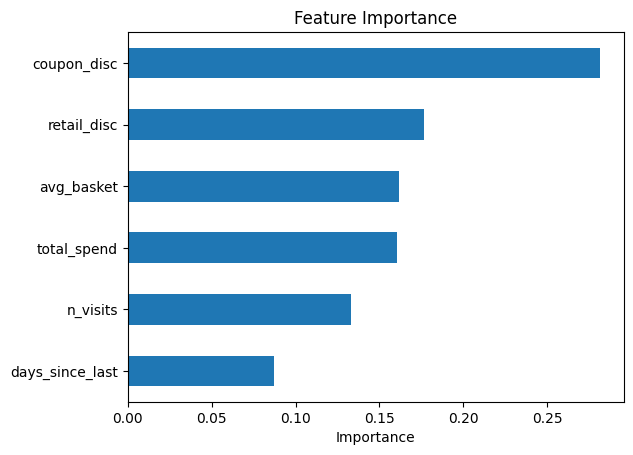

In [25]:
import matplotlib.pyplot as plt

imp = pd.Series(model.feature_importances_, index=features).sort_values()
imp.plot(kind="barh", title="Feature Importance")
plt.xlabel("Importance")
plt.show()

In [26]:
data.groupby(data["coupon_disc"] < 0)["redeemed"].mean().round(3)


coupon_disc
False    0.020
True     0.144
Name: redeemed, dtype: float64

In [27]:
result = data.loc[X_test.index, ["household_id", "campaign_id", "redeemed"]].copy()
result["probability"] = (model.predict_proba(X_test)[:, 1] * 100).round(1)
result.sort_values("probability", ascending=False)

,household_id,campaign_id,redeemed,probability
7168,979,6,0,76.5
799,2489,8,1,74.5
4519,979,7,1,74.0
4269,979,5,1,73.0
6888,88,20,0,72.0
...,...,...,...,...
4723,941,9,0,0.0
4751,634,9,0,0.0
4616,65,7,0,0.0
2531,941,13,0,0.0


In [28]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

pred = model.predict(X_test)
probs = model.predict_proba(X_test)[:, 1]

pd.Series({
    "Accuracy": accuracy_score(y_test, pred),
    "Precision": precision_score(y_test, pred),
    "Recall": recall_score(y_test, pred),
    "F1": f1_score(y_test, pred),
    "ROC-AUC": roc_auc_score(y_test, probs),
    "Baseline (always no)": 1 - y_test.mean(),
}).round(3)

Accuracy                0.871
Precision               0.552
Recall                  0.087
F1                      0.151
ROC-AUC                 0.720
Baseline (always no)    0.869
dtype: float64

In [29]:
pd.DataFrame(confusion_matrix(y_test, pred),
             index=["actual: no", "actual: yes"],
             columns=["predicted: no", "predicted: yes"])

,predicted: no,predicted: yes
actual: no,1197,13
actual: yes,167,16


In [30]:
from sklearn.model_selection import GroupKFold, cross_val_predict

cv_model = RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42)

data["probability"] = cross_val_predict(
    cv_model, X, y,
    groups=data["household_id"],
    cv=GroupKFold(n_splits=5),
    method="predict_proba")[:, 1]

round(roc_auc_score(y, data["probability"]), 3)

0.705

In [31]:
import os

os.makedirs("clean", exist_ok=True)

out = data[["household_id", "campaign_id", "redeemed", "probability"]].round(4)
out.to_csv("clean/coupon_predictions.csv", index=False)